# Tentativo 16 · 5. ModernBERT a 2.048 token

**ModernBERT-base** addestrato (fine-tuning) sui nostri articoli. Ora ogni articolo entra intero: al più 1.500 parole,
circa 2.000 token, dentro una finestra di **2.048 token**, quindi niente tagli e niente pezzi. Rispetto ai tentativi
precedenti (modello sottoallenato: circa 300 passi, 20 articoli per testata) qui ModernBERT vede **tutti gli articoli**
di training a ogni epoca (migliaia di passi), fino a 5 epoche, con learning rate 3e-5.

Prima una **diagnostica su un solo fold** (6 epoche, loss e F1 su validazione e test dopo ogni epoca) per vedere quante
epoche servono. Poi i 5 fold con un **numero di epoche fisso**, scelto dalla diagnostica, su tutte le testate di training
(una validazione di poche testate si è rivelata troppo rumorosa per scegliere l'epoca). Le configurazioni sono quelle del
notebook 3; per tempo si lanciano quelle scelte in `CONFIGURAZIONI`:

| | che cosa impara | su quali articoli | come si decide la testata |
|---|---|---|---|
| **1. 5 classi** | il livello (l1…l5) | tutti | voto degli articoli |
| **2. binario** | affidabile sì/no (punteggio ≥ 60) | tutti | voto degli articoli |
| **3. binario sugli estremi** | affidabile sì/no | solo l1, l2, l4, l5 | voto degli articoli |
| **4. regressione** | il punteggio 0–100 | tutti | media dei punteggi previsti |
| **5. regressione bilanciata** | il punteggio 0–100, ogni livello pesa uguale | tutti | media dei punteggi previsti |
| **6. regressione sugli estremi** | il punteggio 0–100 | solo l1, l2, l4, l5 | media dei punteggi previsti |

Per le regressioni i 5 livelli si ricavano con le **quote del training** (le testate si ordinano per punteggio previsto
e si tagliano con le stesse quote di livelli del training) e "affidabile" = punteggio previsto ≥ 60.

Classificatori: entropia incrociata con classi bilanciate e label smoothing 0,1. Regressori: errore quadratico sul
punteggio. Precisione fp16 (la V100 non supporta bf16).

In [1]:
CONFIGURAZIONI = "regressione,5 classi"   # anche: binario, binario_estremi, regressione_bilanciata, regressione_estremi
DIAGNOSTICA = True                           # prima un fold solo (il 2), 6 epoche, con le curve
EPOCHE = 5                                   # fisso: la diagnostica mostra il plateau dalla 4ª–5ª epoca
VALIDAZIONE = 0.0                            # 0 = niente validazione: tutte le testate di training addestrano, si tiene l'ultima epoca
MAX_TOKEN = 2048
LR = 3e-5
BATCH = 4                                    # batch effettivo 32 (accumulo dei gradienti)
GB_GPU = 14                                  # memoria GPU libera necessaria per partire
PROVA = 0                                    # > 0: solo quel numero di articoli per testata (prova veloce, in Results/prova)

In [2]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed

import funzioni as F

warnings.filterwarnings("ignore"); os.environ["PYTHONWARNINGS"] = "ignore"
OUT = Path("Results/modernbert"); OUT.mkdir(parents=True, exist_ok=True)
art = pd.read_csv("Results/dataset/articoli.csv.gz")
t = pd.read_csv("Results/dataset/testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate, 5 fold")
import time
if PROVA:
    art = art.groupby("domain").head(PROVA).reset_index(drop=True); OUT = Path("Results/prova/modernbert"); OUT.mkdir(parents=True, exist_ok=True)
    print(f"PROVA: {len(art):,} articoli")
LOG = OUT / "avanzamento.log"
def registra(m):
    riga = f"{time.strftime('%Y-%m-%d %H:%M:%S')}  {m}"; print(riga, flush=True)
    with open(LOG, "a") as f:
        f.write(riga + "\n")
SCELTE = [c.strip() for c in CONFIGURAZIONI.split(",") if c.strip()]
print("configurazioni:", SCELTE)

25,524 articoli di 226 testate, 5 fold
configurazioni: ['regressione', '5 classi']


## 0. Diagnostica: quante epoche servono?
Fold 2, 5 classi, 6 epoche. Dopo ogni epoca: loss di training, F1 sulla validazione e sul fold di test (il test qui serve solo a guardare la curva).

2026-10-27 19:23:04  5 classi, fold 2: già fatto, salto


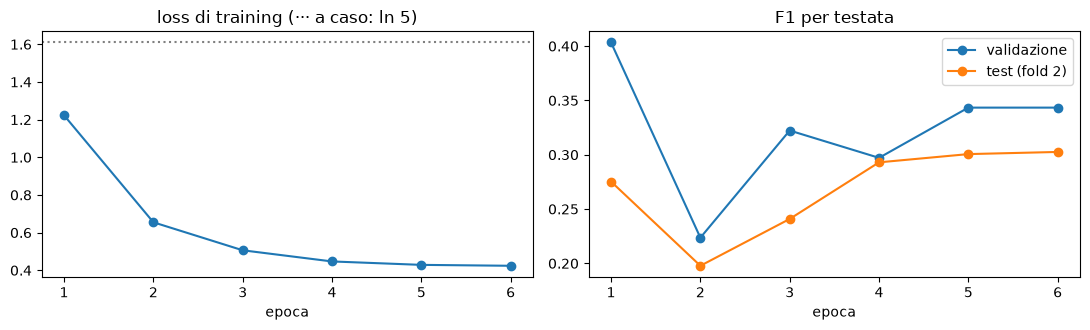

,epoca,loss,validazione,test
0,1,1.223,0.403,0.275
1,2,0.655,0.224,0.198
2,3,0.506,0.322,0.241
3,4,0.447,0.297,0.293
4,5,0.429,0.343,0.301
5,6,0.424,0.343,0.303


In [3]:
# 0.1 un fold solo, 6 epoche, con le curve
if DIAGNOSTICA:
    cartella = OUT / "diagnostica"; cartella.mkdir(exist_ok=True)
    F.modernbert_fold(art, 2, "5 classi", cartella, registra, max_token=MAX_TOKEN, epoche=6, lr=LR, batch=BATCH, gb_gpu=GB_GPU, misura_test=True)
    c = pd.read_csv(cartella / "curva_fold2.csv")
    fig, assi = plt.subplots(1, 2, figsize=(11, 3.4))
    assi[0].plot(c.epoca, c.loss, marker="o"); assi[0].axhline(np.log(5), ls=":", color="grey"); assi[0].set_title("loss di training (··· a caso: ln 5)")
    assi[1].plot(c.epoca, c.validazione, marker="o", label="validazione"); assi[1].plot(c.epoca, c.test, marker="o", label="test (fold 2)")
    assi[1].set_title("F1 per testata"); assi[1].legend()
    for a in assi:
        a.set_xlabel("epoca")
    plt.tight_layout(); plt.savefig(OUT / "diagnostica.png", dpi=160, bbox_inches="tight"); plt.show()
    display(c.round(3))

## 1. Addestramento
Un fold alla volta, una configurazione alla volta. Ogni fold finito si salva: se il notebook si interrompe, si riparte da lì.

In [4]:
# 1.1 tutte le configurazioni scelte, fold per fold
parti = []
for config in SCELTE:
    cartella = OUT / config; cartella.mkdir(exist_ok=True)
    p = pd.concat([F.modernbert_fold(art, k, config, cartella, registra, max_token=MAX_TOKEN, epoche=EPOCHE, lr=LR, batch=BATCH, gb_gpu=GB_GPU,
                                     quota_validazione=VALIDAZIONE) for k in range(1, 6)], ignore_index=True)
    parti.append(p.set_index(["article_id", "domain"]))
pa = pd.concat(parti, axis=1).reset_index()
pa.to_csv(OUT / "previsioni_articoli.csv", index=False)
print(f"{len(pa):,} articoli previsti")

Some weights of ModernBertForSequenceClassification were not initialized from the model checkpoint at answerdotai/ModernBERT-base and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


2026-10-27 19:38:59  regressione, fold 1, epoca 1/5: loss 0.0592 (938 s)


2026-10-27 19:51:15  regressione, fold 1, epoca 2/5: loss 0.0201 (1674 s)


2026-10-27 20:03:16  regressione, fold 1, epoca 3/5: loss 0.0093 (2395 s)


2026-10-27 20:18:52  regressione, fold 1, epoca 4/5: loss 0.0041 (3330 s)


...

2026-10-28 08:11:08  5 classi, fold 5, epoca 3/5: loss 0.5310 (2954 s)


2026-10-28 08:27:33  5 classi, fold 5, epoca 4/5: loss 0.4563 (3939 s)


2026-10-28 08:44:04  5 classi, fold 5, epoca 5/5: loss 0.4350 (4930 s)


2026-10-28 08:45:21  5 classi, fold 5: finito; epoca usata 5, memoria GPU massima 8.1 GB


25,524 articoli previsti


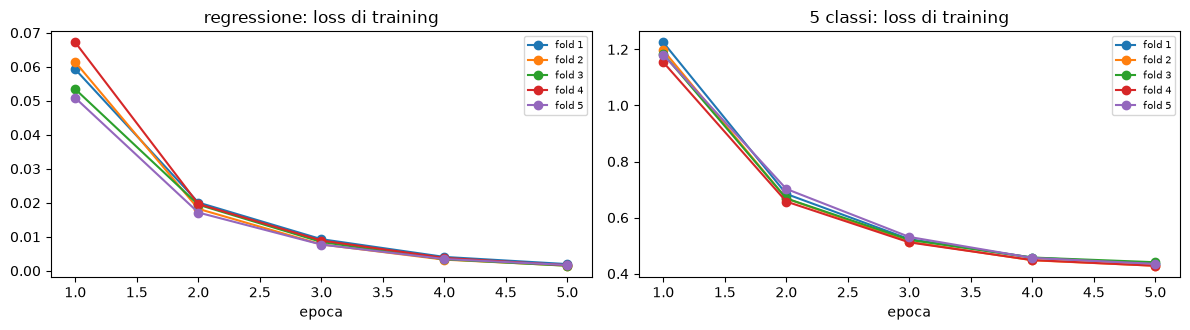

In [5]:
# 1.2 la loss di training epoca per epoca, per ogni fold
fig, assi = plt.subplots(1, len(SCELTE), figsize=(6 * len(SCELTE), 3.4), squeeze=False)
for ax, config in zip(assi[0], SCELTE):
    for k in range(1, 6):
        c = pd.read_csv(OUT / config / f"curva_fold{k}.csv")
        ax.plot(c.epoca, c.loss, marker="o", label=f"fold {k}")
    ax.set_title(f"{config}: loss di training"); ax.set_xlabel("epoca"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT / "curve.png", dpi=160, bbox_inches="tight"); plt.show()

## 2. I risultati

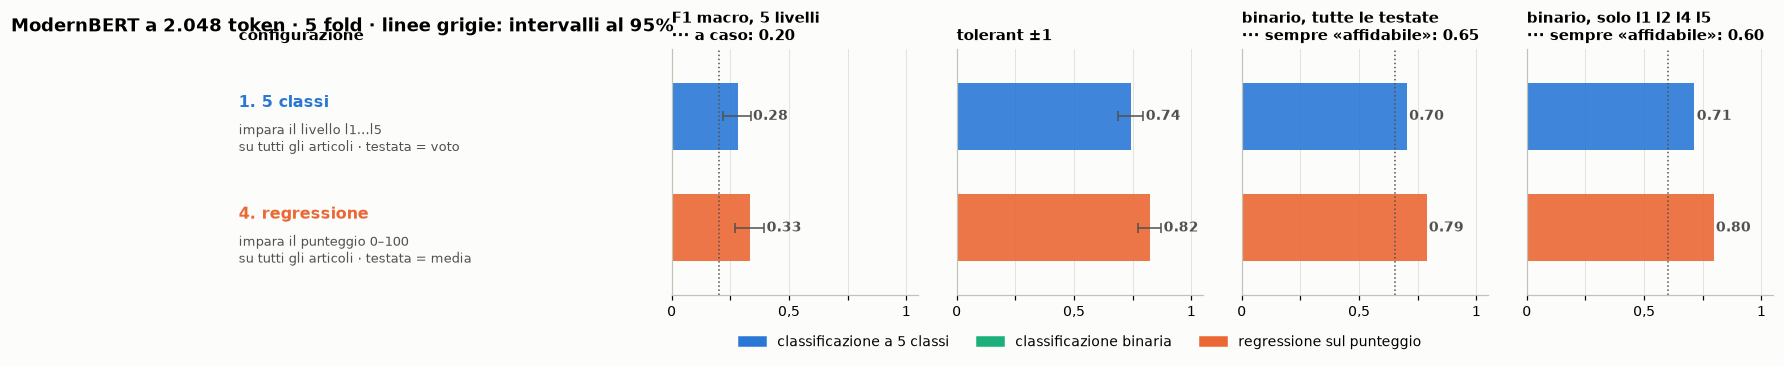

In [6]:
# 2.1 dagli articoli alle testate, le misure (salvate in Results/modernbert), il grafico
T = F.testate_da_articoli(pa, t); T.to_csv(OUT / "previsioni_testate.csv")
tab5, tab2 = F.misure_testate(T); tab5.to_csv(OUT / "cinque_livelli.csv"); tab2.to_csv(OUT / "binario.csv")
F.grafico_riassunto(T, tab5, tab2, "ModernBERT a 2.048 token · 5 fold · linee grigie: intervalli al 95%", OUT / "riassunto.png")